# Task 7: Finalised Classifier Validation

This notebook validates the updated classifier after the Final Mask and Error-based confidence changes. The previous unclassified rate was 97.8%, and the updated classifier is evaluated across 276 intervals from 20 holes.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

classified = pd.read_csv("../data/classified_intervals.csv")

print("Dataset shape:", classified.shape)
print("Number of holes:", classified["hole_id"].nunique())
classified.head()


Dataset shape: (276, 24)
Number of holes: 20


,hole_id,depth,AMPHIBOLE,CARBONATE,CHLORITE,DARK-MICA,EPIDOTE,KAOLIN,OTHER-ALOH,OTHER-MGOH,...,TOURMALINE,WHITE-MICA,total_n,Error,Final Mask,method,label,confidence,rule_fired,reason
0,05GJD001,150.0,0.000000,9.540636,56.183746,22.850412,0.117786,2.120141,0.000000,0.0,...,0.0,8.362780,849,118.292454,1,uTSAS,Unclassified,0.40,R5_no_match,No rule threshold met. Needs expert review.
1,05GJD001,170.0,29.430380,25.886076,22.215190,7.151899,0.126582,1.012658,0.443038,0.0,...,0.0,8.860759,1580,133.013695,1,uTSAS,Possible ore zone,0.65,R2_ore,Carbonate 26% and chlorite 22% exceed provisio...
2,05GJD001,190.0,7.967033,4.890110,69.725275,9.175824,0.054945,0.054945,3.516484,0.0,...,0.0,3.626374,1820,132.354292,1,uTSAS,Unclassified,0.40,R5_no_match,No rule threshold met. Needs expert review.
3,05GJD001,210.0,0.000000,3.728814,68.377724,16.319613,0.048426,0.096852,2.276029,0.0,...,0.0,8.329298,2065,141.432458,1,uTSAS,Unclassified,0.40,R5_no_match,No rule threshold met. Needs expert review.
4,05GJD001,230.0,0.083542,31.161236,15.789474,2.673350,1.336675,0.083542,19.214703,0.0,...,0.0,19.381788,1197,155.696505,1,uTSAS,Possible ore zone,0.59,R2_ore,Carbonate 31% and chlorite 16% exceed provisio...


In [2]:
old_rate = 97.8
new_rate = 89.9

comparison = pd.DataFrame({
    "Classifier Version": [
        "Before Final Mask/Error changes",
        "Updated classifier"
    ],
    "Unclassified Rate (%)": [old_rate, new_rate]
})

comparison


,Classifier Version,Unclassified Rate (%)
0,Before Final Mask/Error changes,97.8
1,Updated classifier,89.9


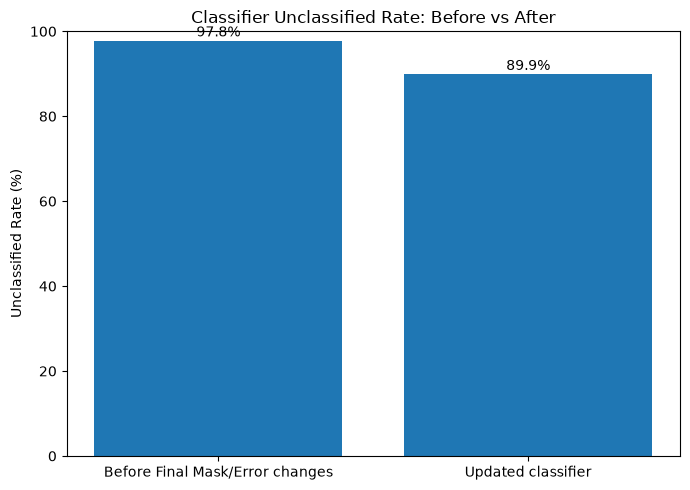

Improvement: 7.9 percentage points


In [3]:
plt.figure(figsize=(7,5))
plt.bar(comparison["Classifier Version"], comparison["Unclassified Rate (%)"])
plt.ylabel("Unclassified Rate (%)")
plt.title("Classifier Unclassified Rate: Before vs After")
plt.ylim(0,100)

for i, value in enumerate(comparison["Unclassified Rate (%)"]):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

print(f"Improvement: {old_rate-new_rate:.1f} percentage points")


In [4]:
EXPECTED_MAX_ERROR = 307

high_error = classified[classified["Error"] > EXPECTED_MAX_ERROR].copy()

print("Total intervals:", len(classified))
print("High Error intervals:", len(high_error))
print("High Error percentage:", round(len(high_error)/len(classified)*100,1), "%")

high_error[
    ["hole_id","depth","Error","Final Mask","label","confidence","rule_fired"]
]


Total intervals: 276
High Error intervals: 69
High Error percentage: 25.0 %


,hole_id,depth,Error,Final Mask,label,confidence,rule_fired
42,07THD003,130.0,329.512188,1,Unclassified,0.25,R5_no_match
62,09ATD015,330.0,405.445998,1,Unclassified,0.25,R5_no_match
63,09ATD015,350.0,348.191172,1,Unclassified,0.25,R5_no_match
84,09DKRCD001A,110.0,403.817545,1,Unclassified,0.25,R5_no_match
91,09DKRCD001A,250.0,317.096245,1,Unclassified,0.25,R5_no_match
...,...,...,...,...,...,...,...
242,09THD033,230.0,347.157107,1,Unclassified,0.25,R5_no_match
245,09THD033,290.0,366.604656,1,Unclassified,0.25,R5_no_match
247,09THD033,330.0,314.770376,1,Unclassified,0.25,R5_no_match
249,09THD033,370.0,310.478088,1,Unclassified,0.25,R5_no_match


In [5]:
print("Rule counts:")
display(classified["rule_fired"].value_counts())

print("\nClassification counts:")
display(classified["label"].value_counts())


Rule counts:


rule_fired
R5_no_match    247
R2_ore          22
R1_phyllic       6
R4_low_data      1
Name: count, dtype: int64


Classification counts:


label
Unclassified         248
Possible ore zone     22
Altered zone           6
Name: count, dtype: int64

## Validation Summary

The updated classifier reduced the unclassified rate from 97.8% to 89.9%, an improvement of 7.9 percentage points. Across 276 analysed intervals, 22 were classified as possible ore zones and 6 as altered zones, while 248 remained unclassified. A total of 69 intervals, or 25.0% of the dataset, exceeded the Error threshold of 307 and should be treated as lower-confidence observations. The changes improved classifier coverage, although the remaining high unclassified rate indicates that rule thresholds and geological validation require further investigation.
